# Actividad 1 — Análisis de la rotación del inventario por película y tienda.

Métricas principales:

- **Índice de rotación:** cantidad de alquileres / cantidad de copias disponibles.
- **Promedio de días de ociosidad:** cantidad de días entre la devolución de una copia y su siguiente alquiler.


## 1. Configuración del entorno


In [1]:
import sys
import pandas as pd
import numpy as np

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
SQL_ACTIVIDAD_1 = PROJECT_ROOT / "sql" / "actividad_1"
sys.path.insert(0, str(PROJECT_ROOT))

from config_conexion import get_engine

## 2. Lectura del conjunto de trabajo

La consulta utilizada para obtener los datos se encuentra en el archivo `sql/actividad_1/conjunto_trabajo.sql`.

Esta consulta devuelve los datos necesarios de inventario y alquileres sin calcular previamente las métricas.


In [2]:
sql_path = SQL_ACTIVIDAD_1 / "conjunto_trabajo.sql"

with open(sql_path, "r", encoding="utf-8") as archivo:
    consulta = archivo.read()

print(consulta)

/*
Construye el conjunto de trabajo crudo para la comparación SQL–pandas.

Se parte de inventario para conservar cada copia física. El LEFT JOIN mantiene
las copias que todavía no tienen alquileres, por lo que alquiler, fecha y
devolucion pueden ser NULL en esos casos.
Cada fila representa una copia y, si existe, uno de sus alquileres.
*/
SELECT
    i.inventario_id AS id,
    i.pelicula_id AS pelicula,
    i.tienda_id AS tienda,
    a.alquiler_id AS alquiler,
    a.fecha_alquiler AS fecha,
    a.fecha_devolucion AS devolucion
FROM inventario AS i
LEFT JOIN alquiler AS a
    ON i.inventario_id = a.inventario_id;



## 3. Carga de datos desde SQL Server


In [3]:
engine = get_engine()

with engine.connect() as conexion:
    df_crudo = pd.read_sql(consulta, conexion)

# La Actividad 2 usa esta copia sin transformaciones.
df = df_crudo.copy()
df_crudo.head()

,id,pelicula,tienda,alquiler,fecha,devolucion
0,367,80,1,1.0,2005-05-24 22:53:30,2005-05-26 22:04:30
1,1525,333,2,2.0,2005-05-24 22:54:33,2005-05-28 19:40:33
2,1711,373,2,3.0,2005-05-24 23:03:39,2005-06-01 22:12:39
3,2452,535,1,4.0,2005-05-24 23:04:41,2005-06-03 01:43:41
4,2079,450,2,5.0,2005-05-24 23:05:21,2005-06-02 04:33:21


## 4. Obtención de la devolución anterior

Para calcular los días de ociosidad es necesario conocer cuándo fue devuelta una copia antes de volver a ser alquilada.

Primero se ordenan los registros por `id` de inventario y fecha de alquiler. Luego se agrupan los registros por copia física mediante `groupby("id")`.

Sobre la columna `devolucion` se aplica `shift(1)`, desplazando las devoluciones una posición dentro de cada copia. De esta manera, cada alquiler puede conocer la fecha de devolución del alquiler inmediatamente anterior.

Esta operación es equivalente conceptualmente a utilizar `LAG(fecha_devolucion)` particionado por inventario en SQL Server.


In [4]:
df = df.sort_values(by=["id", "fecha"]).copy()

df["devolucion_anterior"] = df.groupby("id")["devolucion"].shift(1)

df[["id", "alquiler", "fecha", "devolucion", "devolucion_anterior"]].head(10)

,id,alquiler,fecha,devolucion,devolucion_anterior
4860,1,4863.0,2005-07-08 19:03:15,2005-07-11 21:29:15,NaT
11428,1,11433.0,2005-08-02 20:13:10,2005-08-11 21:35:10,2005-07-11 21:29:15
14709,1,14714.0,2005-08-21 21:27:43,2005-08-30 22:26:43,2005-08-11 21:35:10
970,2,972.0,2005-05-30 20:21:07,2005-06-06 00:36:07,NaT
2115,2,2117.0,2005-06-17 20:24:00,2005-06-23 17:45:00,2005-06-06 00:36:07
4184,2,4187.0,2005-07-07 10:41:31,2005-07-11 06:25:31,2005-06-23 17:45:00
9444,2,9449.0,2005-07-30 22:02:34,2005-08-06 02:09:34,2005-07-11 06:25:31
15448,2,15453.0,2005-08-23 01:01:01,2005-08-30 20:08:01,2005-08-06 02:09:34
10121,3,10126.0,2005-07-31 21:36:07,2005-08-03 23:59:07,NaT
15416,3,15421.0,2005-08-22 23:56:37,2005-08-25 18:58:37,2005-08-03 23:59:07


## 5. Cálculo de los días de ociosidad

Los días de ociosidad representan el tiempo durante el cual una copia permaneció disponible entre dos alquileres consecutivos.

Se calculan restando la devolución del alquiler anterior a la fecha del alquiler actual:

**días de ociosidad = fecha del nuevo alquiler - devolución anterior**

El primer alquiler de cada copia no posee una devolución anterior, por lo que su valor de ociosidad queda como `NaN`. Este valor no debe reemplazarse por cero, ya que cero indicaría que la copia fue alquilada nuevamente el mismo día.


In [5]:
# DATEDIFF(DAY, inicio, fin) cuenta cambios de fecha de calendario.
# Se normalizan las horas para mantener la misma definicion en pandas.
df["dias_ociosidad"] = (
    df["fecha"].dt.normalize() - df["devolucion_anterior"].dt.normalize()
).dt.days

df[["id", "pelicula", "tienda", "fecha", "devolucion_anterior", "dias_ociosidad"]].head(
    10
)

,id,pelicula,tienda,fecha,devolucion_anterior,dias_ociosidad
4860,1,1,1,2005-07-08 19:03:15,NaT,NaN
11428,1,1,1,2005-08-02 20:13:10,2005-07-11 21:29:15,22.0
14709,1,1,1,2005-08-21 21:27:43,2005-08-11 21:35:10,10.0
970,2,1,1,2005-05-30 20:21:07,NaT,NaN
2115,2,1,1,2005-06-17 20:24:00,2005-06-06 00:36:07,11.0
4184,2,1,1,2005-07-07 10:41:31,2005-06-23 17:45:00,14.0
9444,2,1,1,2005-07-30 22:02:34,2005-07-11 06:25:31,19.0
15448,2,1,1,2005-08-23 01:01:01,2005-08-06 02:09:34,17.0
10121,3,1,1,2005-07-31 21:36:07,NaT,NaN
15416,3,1,1,2005-08-22 23:56:37,2005-08-03 23:59:07,19.0


## 6. Promedio de días de ociosidad

Una vez calculada la ociosidad entre alquileres, los registros se agrupan por película y tienda.

Para cada combinación se obtiene la media de `dias_ociosidad` mediante `mean`.

Los valores `NaN`, correspondientes principalmente al primer alquiler de cada copia, no participan del cálculo del promedio (`mean` de pandas los ignora).


In [6]:
ociosidad_promedio = df.groupby(["pelicula", "tienda"], as_index=False).agg(
    promedio_dias_ociosidad=("dias_ociosidad", "mean")
)

ociosidad_promedio.head(10)

,pelicula,tienda,promedio_dias_ociosidad
0,1,1,16.250000
1,1,2,16.250000
2,2,2,59.750000
3,3,2,17.500000
4,4,1,16.444444
5,4,2,44.142857
6,5,2,33.555556
7,6,1,15.125000
8,6,2,13.571429
9,7,1,14.250000


## 7. Cálculo del índice de rotación

El índice de rotación permite relacionar la cantidad de alquileres con la cantidad de copias disponibles de una película en cada tienda.

La fórmula utilizada es:

**índice de rotación = cantidad de alquileres / cantidad de copias**

Para obtener la cantidad de copias se utiliza `nunique` sobre el identificador de inventario. Esto es necesario porque una misma copia puede aparecer varias veces en el conjunto de datos debido a sus distintos alquileres.

Para obtener la cantidad de alquileres se utiliza `count` sobre la columna `alquiler`. Los valores nulos no se cuentan, por lo que las copias que nunca fueron alquiladas permanecen en el inventario pero no incrementan la cantidad de alquileres.


In [7]:
rotacion = df.groupby(["pelicula", "tienda"], as_index=False).agg(
    cantidad_copias=("id", "nunique"), cantidad_alquileres=("alquiler", "count")
)

rotacion["indice_rotacion"] = (
    rotacion["cantidad_alquileres"] / rotacion["cantidad_copias"]
)

rotacion.head(10)

,pelicula,tienda,cantidad_copias,cantidad_alquileres,indice_rotacion
0,1,1,4,12,3.000000
1,1,2,4,11,2.750000
2,2,2,3,7,2.333333
3,3,2,4,12,3.000000
4,4,1,4,13,3.250000
5,4,2,3,10,3.333333
6,5,2,3,12,4.000000
7,6,1,3,11,3.666667
8,6,2,3,10,3.333333
9,7,1,2,6,3.000000


## 8. Resultado de las métricas calculadas con pandas

Finalmente se combinan los resultados de rotación y ociosidad mediante las columnas `pelicula` y `tienda`.

El DataFrame resultante contiene, para cada película y tienda:

- cantidad de copias;
- cantidad de alquileres;
- índice de rotación;
- promedio de días de ociosidad.

Este resultado podrá compararse posteriormente con las mismas métricas calculadas directamente en T-SQL.


In [8]:
resultado_pandas = rotacion.merge(
    ociosidad_promedio, on=["pelicula", "tienda"], how="left"
)

resultado_pandas.head(10)

,pelicula,tienda,cantidad_copias,cantidad_alquileres,indice_rotacion,promedio_dias_ociosidad
0,1,1,4,12,3.000000,16.250000
1,1,2,4,11,2.750000,16.250000
2,2,2,3,7,2.333333,59.750000
3,3,2,4,12,3.000000,17.500000
4,4,1,4,13,3.250000,16.444444
5,4,2,3,10,3.333333,44.142857
6,5,2,3,12,4.000000,33.555556
7,6,1,3,11,3.666667,15.125000
8,6,2,3,10,3.333333,13.571429
9,7,1,2,6,3.000000,14.250000


## 9. Ejecución de la métrica en T-SQL

La misma métrica se ejecuta en SQL Server desde `sql/actividad_1/metricas_rotacion.sql`, sin copiar la consulta dentro del notebook. SQL Server usa `LAG` y agrupa por película y tienda. Se mide la consulta completa para informar su tiempo por separado.


In [9]:
from time import perf_counter

consulta_metricas = (SQL_ACTIVIDAD_1 / "metricas_rotacion.sql").read_text(
    encoding="utf-8"
)
tiempos_sql = []
for _ in range(10):
    inicio = perf_counter()
    with engine.connect() as conexion:
        resultado_sql = pd.read_sql(consulta_metricas, conexion)
    tiempos_sql.append(perf_counter() - inicio)

resultado_sql.head()  # type: ignore

,pelicula,tienda,cantidad_copias,cantidad_alquileres,indice_rotacion,promedio_dias_ociosidad
0,1,1,4,12,3.000000,16.250000
1,1,2,4,11,2.750000,16.250000
2,2,2,3,7,2.333333,59.750000
3,3,2,4,12,3.000000,17.500000
4,4,1,4,13,3.250000,16.444444


## 10. Comparación entre T-SQL y pandas

Los resultados se unen por `pelicula` y `tienda`. Los conteos se comparan exactamente y las métricas decimales se validan antes de aplicar formato de presentación.

### Hallazgo sobre redondeo

En una comparación inicial se observaron diferencias de 0,01 en algunos promedios de días de ociosidad. La revisión mostró que la fórmula era equivalente, pero ambas implementaciones reducían el promedio a dos decimales antes de compararlo. En valores situados en un punto intermedio, SQL Server y pandas pueden resolver el redondeo de manera diferente.

Por ese motivo, `metricas_rotacion.sql` conserva doce decimales y pandas mantiene los valores sin `.round(2)`. La validación usa `assert_frame_equal` con una tolerancia absoluta de `1e-9`, limitada a la representación numérica de punto flotante. El formato de dos decimales queda reservado para una eventual presentación, no para calcular ni validar.


In [10]:
claves = ["pelicula", "tienda"]

columnas_decimales = ["indice_rotacion", "promedio_dias_ociosidad"]

sql_comparacion = resultado_sql.sort_values(claves).reset_index(drop=True).copy()

pandas_comparacion = resultado_pandas.sort_values(claves).reset_index(drop=True).copy()

for columna in columnas_decimales:
    sql_comparacion[columna] = pd.to_numeric(
        sql_comparacion[columna], errors="raise"
    ).astype(float)

    pandas_comparacion[columna] = pd.to_numeric(
        pandas_comparacion[columna], errors="raise"
    ).astype(float)

validacion_equivalente = False

try:
    pd.testing.assert_frame_equal(
        sql_comparacion,
        pandas_comparacion,
        check_dtype=False,
        check_exact=False,
        rtol=0,
        atol=1e-9,
    )

    validacion_equivalente = True
    print("VALIDACIÓN EXITOSA")
    print("-" * 45)
    print(f"Filas comparadas:        {len(sql_comparacion)}")
    print(f"Columnas comparadas:     {len(sql_comparacion.columns)}")
    print(f"Grupos película/tienda:  {len(sql_comparacion)}")
    print(f"Tolerancia numérica:     1e-9")
    print()
    print("Resultados:")
    print("Cantidad de copias coincide")
    print("Cantidad de alquileres coincide")
    print("Índice de rotación coincide")
    print("Promedio de ociosidad coincide")
    print()
    print("Conclusión:")
    print("T-SQL y pandas producen resultados equivalentes.")

except AssertionError as error:
    print("VALIDACIÓN FALLIDA")
    print("-" * 45)
    print("Se encontraron diferencias entre T-SQL y pandas.")
    print()
    print(error)

VALIDACIÓN EXITOSA
---------------------------------------------
Filas comparadas:        1521
Columnas comparadas:     6
Grupos película/tienda:  1521
Tolerancia numérica:     1e-9

Resultados:
Cantidad de copias coincide
Cantidad de alquileres coincide
Índice de rotación coincide
Promedio de ociosidad coincide

Conclusión:
T-SQL y pandas producen resultados equivalentes.


## 11. Medición de tiempos

El tiempo de T-SQL incluye ejecutar la consulta agregada y recibir su resultado desde SQL Server. El de pandas mide solamente ordenar, aplicar `groupby`/`shift` y calcular/agrupar métricas sobre el DataFrame ya cargado. Se hacen tres repeticiones y se informa el promedio; no permiten sacar conclusiones absolutas de rendimiento.


In [11]:
def calcular_metricas_pandas(datos_crudos):
    datos = datos_crudos.sort_values(["id", "fecha"]).copy()
    datos["devolucion_anterior"] = datos.groupby("id")["devolucion"].shift(1)
    datos["dias_ociosidad"] = (
        datos["fecha"].dt.normalize() - datos["devolucion_anterior"].dt.normalize()
    ).dt.days
    ociosidad = datos.groupby(["pelicula", "tienda"], as_index=False).agg(
        promedio_dias_ociosidad=("dias_ociosidad", "mean")
    )
    rotacion_temporal = datos.groupby(["pelicula", "tienda"], as_index=False).agg(
        cantidad_copias=("id", "nunique"), cantidad_alquileres=("alquiler", "count")
    )
    rotacion_temporal["indice_rotacion"] = (
        rotacion_temporal["cantidad_alquileres"] / rotacion_temporal["cantidad_copias"]
    )
    return rotacion_temporal.merge(ociosidad, on=["pelicula", "tienda"], how="left")


tiempos_pandas = []
for _ in range(10):
    inicio = perf_counter()
    resultado_pandas_temporal = calcular_metricas_pandas(
        df.drop(columns=["devolucion_anterior", "dias_ociosidad"])
    )
    tiempos_pandas.append(perf_counter() - inicio)
assert resultado_pandas_temporal.equals(resultado_pandas)  # type: ignore
tabla_tiempos = pd.DataFrame(
    {
        "implementacion": ["T-SQL", "pandas"],
        "promedio_segundos": [np.mean(tiempos_sql), np.mean(tiempos_pandas)],
        "minimo_segundos": [np.min(tiempos_sql), np.min(tiempos_pandas)],
        "repeticiones": [len(tiempos_sql), len(tiempos_pandas)],
    }
)
tabla_tiempos

,implementacion,promedio_segundos,minimo_segundos,repeticiones
0,T-SQL,0.047121,0.046049,10
1,pandas,0.012556,0.012153,10


## 12. Conclusión de la Actividad 1

La implementación en T-SQL y la implementación vectorizada en pandas producen métricas equivalentes para cada combinación de película y tienda, dentro de la tolerancia numérica definida. La diferencia observada en los valores mostrados se explica por el redondeo de presentación, no por una diferencia de cálculo.

En esta medición, pandas resultó más rápido porque calcula sobre un `DataFrame` ya cargado en memoria, mientras que el tiempo de T-SQL incluye la ejecución de la consulta en SQL Server y la transferencia del resultado. Esta comparación no permite afirmar que pandas sea siempre más eficiente: con volúmenes mayores, filtros o agregaciones más costosas, es esperable que SQL Server tenga ventajas al procesar los datos cerca de su almacenamiento.

Por esta razón, se utiliza SQL Server para construir, filtrar y agregar el conjunto de trabajo, y pandas para transformaciones analíticas y validación de resultados.


# Actividad 2 — Perfilado y diagnóstico de calidad

Los controles se ejecutan sobre `df_crudo`, antes de las transformaciones usadas para comparar las métricas de la Actividad 1.


## 13. Reconocimiento inicial

Se revisan dimensiones, tipos, ejemplos y estadísticos descriptivos sin modificar los datos.


In [12]:
print(f"Dimensiones: {df_crudo.shape[0]} filas y {df_crudo.shape[1]} columnas")

print("\nTipos:")
display(df_crudo.dtypes.rename("tipo").to_frame())

print("\nPrimeras Filas:")
display(df_crudo.head())

print("\nMuestra Aleatoria (5):")
display(df_crudo.sample(n=5, random_state=1))

print("\nInfo:")
df_crudo.info()

print("\nDescribe:")
display(df_crudo.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]))

Dimensiones: 16045 filas y 6 columnas

Tipos:


,tipo
id,int64
pelicula,int64
tienda,int64
alquiler,float64
fecha,datetime64[us]
devolucion,datetime64[us]



Primeras Filas:


,id,pelicula,tienda,alquiler,fecha,devolucion
0,367,80,1,1.0,2005-05-24 22:53:30,2005-05-26 22:04:30
1,1525,333,2,2.0,2005-05-24 22:54:33,2005-05-28 19:40:33
2,1711,373,2,3.0,2005-05-24 23:03:39,2005-06-01 22:12:39
3,2452,535,1,4.0,2005-05-24 23:04:41,2005-06-03 01:43:41
4,2079,450,2,5.0,2005-05-24 23:05:21,2005-06-02 04:33:21



Muestra Aleatoria (5):


,id,pelicula,tienda,alquiler,fecha,devolucion
5306,4026,877,1,5309.0,2005-07-09 16:00:16,2005-07-17 17:56:16
10937,2304,501,1,10942.0,2005-08-02 03:16:31,2005-08-11 02:46:31
11343,1704,371,1,11348.0,2005-08-02 17:18:38,2005-08-06 16:11:38
8160,1674,366,1,8164.0,2005-07-28 21:17:19,2005-07-30 21:12:19
10386,2203,476,2,10391.0,2005-08-01 06:49:05,2005-08-04 01:51:05



Info:
<class 'pandas.DataFrame'>
RangeIndex: 16045 entries, 0 to 16044
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   id          16045 non-null  int64         
 1   pelicula    16045 non-null  int64         
 2   tienda      16045 non-null  int64         
 3   alquiler    16044 non-null  float64       
 4   fecha       16044 non-null  datetime64[us]
 5   devolucion  15861 non-null  datetime64[us]
dtypes: datetime64[us](2), float64(1), int64(3)
memory usage: 752.2 KB

Describe:


,id,pelicula,tienda,alquiler,fecha,devolucion
count,16045.000000,16045.000000,16045.000000,16044.000000,16044,15861
mean,2291.700031,501.077719,1.506201,8025.371478,2005-07-23 08:12:53.217526,2005-07-25 23:58:03.138768
min,1.000000,1.000000,1.000000,1.000000,2005-05-24 22:53:30,2005-05-25 23:55:21
5%,230.000000,51.000000,1.000000,804.150000,2005-05-29 18:11:35.100000,2005-06-04 03:23:13
25%,1154.000000,255.000000,1.000000,4013.750000,2005-07-07 00:58:40.500000,2005-07-10 15:49:36
50%,2291.000000,496.000000,2.000000,8025.500000,2005-07-28 16:04:32.500000,2005-08-01 19:45:29
75%,3433.000000,753.000000,2.000000,12037.250000,2005-08-17 21:16:23,2005-08-20 23:35:55
95%,4360.000000,951.000000,2.000000,15245.850000,2005-08-22 23:11:48.500000,2005-08-28 16:10:09
max,4581.000000,1000.000000,2.000000,16049.000000,2006-02-14 15:16:03,2005-09-02 02:35:22
std,1322.292689,288.531551,0.499977,4632.777249,NaN,NaN


## 14. Controles en pandas

Los faltantes, duplicados, reglas de negocio, cobertura temporal y atípicos se calculan sobre el conjunto crudo. Para IQR se usa el índice de rotación por película y tienda.

In [13]:
faltantes = pd.DataFrame(
    {
        "cantidad": df_crudo.isna().sum(),
        "porcentaje": (df_crudo.isna().mean() * 100).round(2),
    }
)

alquileres = df_crudo[df_crudo["alquiler"].notna()].copy()

grupos_alquiler_duplicados = alquileres.loc[
    alquileres.duplicated("alquiler", keep=False), "alquiler"
].nunique()

grupos_id_alquiler_duplicados = (
    alquileres.loc[
        alquileres.duplicated(["id", "alquiler"], keep=False), ["id", "alquiler"]
    ]
    .drop_duplicates()
    .shape[0]
)

devolucion_antes_alquiler = (
    (alquileres["devolucion"].notna())
    & (alquileres["devolucion"] < alquileres["fecha"])
).sum()

alquileres_sin_referencia = (
    alquileres[["id", "pelicula", "tienda"]].isna().any(axis=1).sum()
)

copias_inconsistentes = (
    (df_crudo.groupby("id")[["pelicula", "tienda"]].nunique() > 1).any(axis=1).sum()
)

valores_unicos = df_crudo.nunique(dropna=False).rename("valores_unicos").to_frame()

columnas_constantes = valores_unicos[valores_unicos["valores_unicos"] == 1]

cobertura = pd.DataFrame(
    {
        "minima": [df_crudo["fecha"].min(), df_crudo["devolucion"].min()],
        "maxima": [df_crudo["fecha"].max(), df_crudo["devolucion"].max()],
    },
    index=["fecha_alquiler", "fecha_devolucion"],
)

q1, q3 = resultado_pandas["indice_rotacion"].quantile([0.25, 0.75])

iqr = q3 - q1

limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr

atipicos_rotacion = resultado_pandas[
    (resultado_pandas["indice_rotacion"] < limite_inferior)
    | (resultado_pandas["indice_rotacion"] > limite_superior)
]

copias_nunca_alquiladas = df_crudo[df_crudo["alquiler"].isna()][
    ["id", "pelicula", "tienda"]
].drop_duplicates()

with engine.connect() as conexion:
    catalogo = pd.read_sql("SELECT pelicula_id AS pelicula FROM pelicula", conexion)

peliculas_sin_copias = catalogo[
    ~catalogo["pelicula"].isin(df_crudo["pelicula"].dropna())
]

print("\nValores faltantes")
display(faltantes)

print("\nDuplicados e inconsistencias")
display(
    pd.DataFrame(
        {
            "grupos_alquiler_duplicados": [grupos_alquiler_duplicados],
            "grupos_id_alquiler_duplicados": [grupos_id_alquiler_duplicados],
            "devoluciones_anteriores_alquiler": [devolucion_antes_alquiler],
            "alquileres_sin_referencia": [alquileres_sin_referencia],
            "copias_inconsistentes": [copias_inconsistentes],
        }
    )
)

print("\nValores únicos por columna")
display(valores_unicos)

print("\nCobertura temporal")
display(cobertura)

print("\nValores atípicos de rotación")
display(
    pd.DataFrame(
        {
            "Q1": [q1],
            "Q3": [q3],
            "IQR": [iqr],
            "limite_inferior": [limite_inferior],
            "limite_superior": [limite_superior],
            "atipicos": [len(atipicos_rotacion)],
        }
    )
)

print("\nCopias y películas sin actividad")
print(f"Copias nunca alquiladas: {len(copias_nunca_alquiladas)}")
print(f"Películas sin copias: {len(peliculas_sin_copias)}")

print("\nColumnas constantes y valores categóricos")
print(f"Columnas constantes: {list(columnas_constantes.index)}")
print(f"Tiendas presentes: {sorted(df_crudo['tienda'].dropna().unique().tolist())}")

print("\nValidaciones temporales y rangos")
print(
    f"Alquileres posteriores a la última devolución registrada: "
    f"{(df_crudo['fecha'] > df_crudo['devolucion'].max()).sum()}"
)

print(
    f"Rotación mínima y máxima: "
    f"{resultado_pandas['indice_rotacion'].min():.2f} y "
    f"{resultado_pandas['indice_rotacion'].max():.2f}"
)

if atipicos_rotacion.empty:
    print("\nNo se detectaron valores atípicos, no hay casos que clasificar.")
else:
    display(atipicos_rotacion)


Valores faltantes


,cantidad,porcentaje
id,0,0.00
pelicula,0,0.00
tienda,0,0.00
alquiler,1,0.01
fecha,1,0.01
devolucion,184,1.15



Duplicados e inconsistencias


,grupos_alquiler_duplicados,grupos_id_alquiler_duplicados,devoluciones_anteriores_alquiler,alquileres_sin_referencia,copias_inconsistentes
0,0,0,0,0,0



Valores únicos por columna


...


Cobertura temporal


,minima,maxima
fecha_alquiler,2005-05-24 22:53:30,2006-02-14 15:16:03
fecha_devolucion,2005-05-25 23:55:21,2005-09-02 02:35:22



Valores atípicos de rotación


,Q1,Q3,IQR,limite_inferior,limite_superior,atipicos
0,3.0,4.0,1.0,1.5,5.5,0



Copias y películas sin actividad
Copias nunca alquiladas: 1
Películas sin copias: 42

Columnas constantes y valores categóricos
Columnas constantes: []
Tiendas presentes: [1, 2]

Validaciones temporales y rangos
Alquileres posteriores a la última devolución registrada: 182
Rotación mínima y máxima: 2.00 y 5.00

No se detectaron valores atípicos, no hay casos que clasificar.


## 15. Verificación en T-SQL

Se repiten en SQL Server los controles de faltantes y duplicados, y los controles específicos de la variante. Los resultados se comparan con pandas.


In [14]:
consulta_faltantes_sql = """
SELECT
    SUM(CASE WHEN a.alquiler_id IS NULL THEN 1 ELSE 0 END) AS alquiler_nulo,
    SUM(CASE WHEN a.fecha_alquiler IS NULL THEN 1 ELSE 0 END) AS fecha_nula,
    SUM(CASE WHEN a.fecha_devolucion IS NULL THEN 1 ELSE 0 END) AS devolucion_nula
FROM inventario AS i
LEFT JOIN alquiler AS a ON a.inventario_id = i.inventario_id;
"""
consulta_duplicados_sql = """
SELECT COUNT(*) AS grupos_alquiler_duplicados
FROM (
    SELECT alquiler_id
    FROM alquiler
    GROUP BY alquiler_id
    HAVING COUNT(*) > 1
) AS duplicados;
"""
consulta_especifico_sql = """
SELECT
    (SELECT COUNT(*) FROM inventario AS i WHERE NOT EXISTS (SELECT 1 FROM alquiler AS a WHERE a.inventario_id = i.inventario_id)) AS copias_nunca_alquiladas,
    (SELECT COUNT(*) FROM pelicula AS p WHERE NOT EXISTS (SELECT 1 FROM inventario AS i WHERE i.pelicula_id = p.pelicula_id)) AS peliculas_sin_copias;
"""
with engine.connect() as conexion:
    faltantes_sql = pd.read_sql(consulta_faltantes_sql, conexion)
    duplicados_sql = pd.read_sql(consulta_duplicados_sql, conexion)
    especifico_sql = pd.read_sql(consulta_especifico_sql, conexion)

display(faltantes_sql)
display(duplicados_sql)
display(especifico_sql)

,alquiler_nulo,fecha_nula,devolucion_nula
0,1,1,184


,grupos_alquiler_duplicados
0,0


,copias_nunca_alquiladas,peliculas_sin_copias
0,1,42


## 16. Comparación y decisión

Se verifican los controles replicados. Las decisiones distinguen faltantes válidos propios del dominio de inconsistencias que exigirían tratamiento.


In [15]:
comparacion_controles = pd.DataFrame(
    {
        "control": [
            "alquileres faltantes",
            "fechas de alquiler faltantes",
            "devoluciones faltantes",
            "grupos de alquiler duplicados",
            "copias nunca alquiladas",
            "películas sin copias",
        ],
        "pandas": [
            faltantes.loc["alquiler", "cantidad"],
            faltantes.loc["fecha", "cantidad"],
            faltantes.loc["devolucion", "cantidad"],
            grupos_alquiler_duplicados,
            len(copias_nunca_alquiladas),
            len(peliculas_sin_copias),
        ],
        "t_sql": [
            faltantes_sql.loc[0, "alquiler_nulo"],
            faltantes_sql.loc[0, "fecha_nula"],
            faltantes_sql.loc[0, "devolucion_nula"],
            duplicados_sql.loc[0, "grupos_alquiler_duplicados"],
            especifico_sql.loc[0, "copias_nunca_alquiladas"],
            especifico_sql.loc[0, "peliculas_sin_copias"],
        ],
    }
)
comparacion_controles["coinciden"] = (
    comparacion_controles["pandas"]
    .astype(int)
    .eq(comparacion_controles["t_sql"].astype(int))
)
assert comparacion_controles["coinciden"].all()
display(comparacion_controles)

print(
    "Decisión: se conservan los faltantes de alquiler y devolución cuando representan, respectivamente,\n copias nunca alquiladas y alquileres abiertos. Las reglas de negocio, duplicados y atípicos se interpretan\n con los resultados mostrados arriba antes de definir cualquier exclusión."
)

,control,pandas,t_sql,coinciden
0,alquileres faltantes,1,1,True
1,fechas de alquiler faltantes,1,1,True
2,devoluciones faltantes,184,184,True
3,grupos de alquiler duplicados,0,0,True
4,copias nunca alquiladas,1,1,True
5,películas sin copias,42,42,True


Decisión: se conservan los faltantes de alquiler y devolución cuando representan, respectivamente,
 copias nunca alquiladas y alquileres abiertos. Las reglas de negocio, duplicados y atípicos se interpretan
 con los resultados mostrados arriba antes de definir cualquier exclusión.


# Actividad 3 — Análisis y visualización narrativa

Esta actividad responde qué copias muestran rotación durante el período observado y si hay evidencia para redistribuir inventario entre las dos tiendas. Se reutiliza el conjunto crudo de la Actividad 1 y se conservan las decisiones de calidad de la Actividad 2: la copia sin alquileres permanece en el denominador y las devoluciones faltantes no se reemplazan.

Los resultados describen el período disponible en la base.

## 17. Vistas de análisis y cálculo vectorizado

Se separan dos vistas sin modificar `df_crudo`:

- `copias_analisis`: una fila por copia, para que el denominador de rotación sea correcto.
- `alquileres_validos`: sólo alquileres reales con fecha, para contar el numerador y ordenar los eventos de cada copia.

La ociosidad se calcula con `groupby` y `shift`: para cada alquiler se resta la devolución del alquiler anterior de la fecha del nuevo alquiler. Las filas que no tienen devolución anterior o no tienen devolución se conservan, pero no aportan un intervalo de ociosidad medible.

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

GRAFICOS_DIR = PROJECT_ROOT / "graficos"
GRAFICOS_DIR.mkdir(exist_ok=True)

PALETA_TIENDAS = {1: "#2F6B8A", 2: "#E07A5F"}
sns.set_theme(style="whitegrid", context="notebook")

# Una copia debe pertenecer siempre a una única película y a una única tienda.
copias_analisis = df_crudo[["id", "pelicula", "tienda"]].drop_duplicates().copy()
copias_inconsistentes_a3 = (
    df_crudo.groupby("id")[["pelicula", "tienda"]].nunique().gt(1).any(axis=1)
)
assert (
    not copias_inconsistentes_a3.any()
), "Hay copias asociadas a más de una película o tienda."

# La única fila sin alquiler ni fecha queda en la vista de copias, no en la de alquileres.
alquileres_validos = df_crudo.loc[
    df_crudo["alquiler"].notna() & df_crudo["fecha"].notna()
].copy()
assert not alquileres_validos.duplicated("alquiler").any(), "Hay alquileres duplicados."

alquileres_validos = alquileres_validos.sort_values(["id", "fecha"]).copy()
alquileres_validos["devolucion_anterior"] = alquileres_validos.groupby("id")[
    "devolucion"
].shift(1)
alquileres_validos["dias_ociosidad"] = (
    alquileres_validos["fecha"].dt.normalize()
    - alquileres_validos["devolucion_anterior"].dt.normalize()
).dt.days

assert not (
    alquileres_validos["dias_ociosidad"].dropna() < 0
).any(), "Se encontraron intervalos de ociosidad negativos."

copias_por_pelicula_tienda = copias_analisis.groupby(
    ["pelicula", "tienda"], as_index=False
).agg(cantidad_copias=("id", "nunique"))

alquileres_por_pelicula_tienda = alquileres_validos.groupby(
    ["pelicula", "tienda"], as_index=False
).agg(cantidad_alquileres=("alquiler", "nunique"))

ociosidad_por_pelicula_tienda = alquileres_validos.groupby(
    ["pelicula", "tienda"], as_index=False
).agg(
    promedio_dias_ociosidad=("dias_ociosidad", "mean"),
    intervalos_con_ocio=("dias_ociosidad", "count"),
)

metricas_visualizacion = copias_por_pelicula_tienda.merge(
    alquileres_por_pelicula_tienda, on=["pelicula", "tienda"], how="left"
).merge(ociosidad_por_pelicula_tienda, on=["pelicula", "tienda"], how="left")
metricas_visualizacion["cantidad_alquileres"] = (
    metricas_visualizacion["cantidad_alquileres"].fillna(0).astype("int64")
)
metricas_visualizacion["indice_rotacion"] = (
    metricas_visualizacion["cantidad_alquileres"]
    / metricas_visualizacion["cantidad_copias"]
)

# Esta vista a nivel de intervalo alimenta el gráfico de caja y bigotes.
intervalos_ocio = alquileres_validos.dropna(subset=["dias_ociosidad"]).copy()

print(f"Copias únicas: {len(copias_analisis):,}")
print(f"Alquileres reales con fecha: {len(alquileres_validos):,}")
print(f"Intervalos de ociosidad medibles: {len(intervalos_ocio):,}")
display(metricas_visualizacion.head())

Copias únicas: 4,581
Alquileres reales con fecha: 16,044
Intervalos de ociosidad medibles: 11,464


,pelicula,tienda,cantidad_copias,cantidad_alquileres,promedio_dias_ociosidad,intervalos_con_ocio,indice_rotacion
0,1,1,4,12,16.250000,8,3.000000
1,1,2,4,11,16.250000,8,2.750000
2,2,2,3,7,59.750000,4,2.333333
3,3,2,4,12,17.500000,8,3.000000
4,4,1,4,13,16.444444,9,3.250000


## 18. Validación de las métricas que alimentan los gráficos

Antes de graficar se verifica que el total de copias coincida con la vista única, que cada alquiler se cuente una sola vez y que la ociosidad no tenga valores negativos. La tabla breve muestra los quince extremos de cada lado que se usarán en el gráfico de barras.

In [17]:
validacion_actividad_3 = pd.DataFrame(
    {
        "control": [
            "copias en la vista única",
            "copias en los grupos de métricas",
            "alquileres reales únicos",
            "alquileres contados en los grupos",
            "intervalos de ociosidad negativos",
        ],
        "valor": [
            len(copias_analisis),
            metricas_visualizacion["cantidad_copias"].sum(),
            alquileres_validos["alquiler"].nunique(),
            metricas_visualizacion["cantidad_alquileres"].sum(),
            (intervalos_ocio["dias_ociosidad"] < 0).sum(),
        ],
    }
)

assert validacion_actividad_3.loc[0, "valor"] == validacion_actividad_3.loc[1, "valor"]
assert validacion_actividad_3.loc[2, "valor"] == validacion_actividad_3.loc[3, "valor"]
assert validacion_actividad_3.loc[4, "valor"] == 0

resumen_metricas_a3 = metricas_visualizacion.groupby("tienda", as_index=False).agg(
    peliculas_tienda=("pelicula", "size"),
    copias=("cantidad_copias", "sum"),
    alquileres=("cantidad_alquileres", "sum"),
    rotacion_media=("indice_rotacion", "mean"),
    rotacion_mediana=("indice_rotacion", "median"),
    ociosidad_media=("promedio_dias_ociosidad", "mean"),
)

extremos_mayores = metricas_visualizacion.sort_values(
    ["indice_rotacion", "cantidad_alquileres", "pelicula", "tienda"],
    ascending=[False, False, True, True],
).head(15).copy()
extremos_menores = metricas_visualizacion.sort_values(
    ["indice_rotacion", "cantidad_alquileres", "pelicula", "tienda"],
    ascending=[True, True, True, True],
).head(15).copy()

tabla_insumo_barras = pd.concat(
    [
        extremos_mayores.assign(extremo="15 mayores"),
        extremos_menores.assign(extremo="15 menores"),
    ],
    ignore_index=True,
)[
    [
        "extremo",
        "pelicula",
        "tienda",
        "cantidad_copias",
        "cantidad_alquileres",
        "indice_rotacion",
        "promedio_dias_ociosidad",
    ]
].sort_values(["extremo", "indice_rotacion", "pelicula"])

display(validacion_actividad_3)
display(resumen_metricas_a3.round(2))
display(tabla_insumo_barras.round(2))

print("Nulos de promedio de ociosidad:", metricas_visualizacion["promedio_dias_ociosidad"].isna().sum())
print("Rango del índice de rotación:", f"{metricas_visualizacion['indice_rotacion'].min():.2f}", "a", f"{metricas_visualizacion['indice_rotacion'].max():.2f}")

,control,valor
0,copias en la vista única,4581
1,copias en los grupos de métricas,4581
2,alquileres reales únicos,16044
3,alquileres contados en los grupos,16044
4,intervalos de ociosidad negativos,0


,tienda,peliculas_tienda,copias,alquileres,rotacion_media,rotacion_mediana,ociosidad_media
0,1,759,2270,7923,3.50,3.5,19.33
1,2,762,2311,8121,3.52,3.5,19.22


,extremo,pelicula,tienda,cantidad_copias,cantidad_alquileres,indice_rotacion,promedio_dias_ociosidad
12,15 mayores,15,1,2,10,5.0,16.25
13,15 mayores,21,1,2,10,5.0,16.50
14,15 mayores,23,2,2,10,5.0,15.00
2,15 mayores,28,1,3,15,5.0,16.75
3,15 mayores,395,1,3,15,5.0,15.67
4,15 mayores,442,1,3,15,5.0,16.17
0,15 mayores,450,2,4,20,5.0,16.38
1,15 mayores,535,1,4,20,5.0,16.19
5,15 mayores,770,2,3,15,5.0,17.58
6,15 mayores,775,1,3,15,5.0,15.83


Nulos de promedio de ociosidad: 0
Rango del índice de rotación: 2.00 a 5.00


## 19. Gráficos

Los tres gráficos se guardan en `graficos/`. El gráfico de barras se incluye porque es obligatorio, pero sus empates son un resultado en sí mismo: selecciona sólo quince casos entre varias películas con el mismo valor extremo; no debe leerse como un ranking estricto entre esas películas.

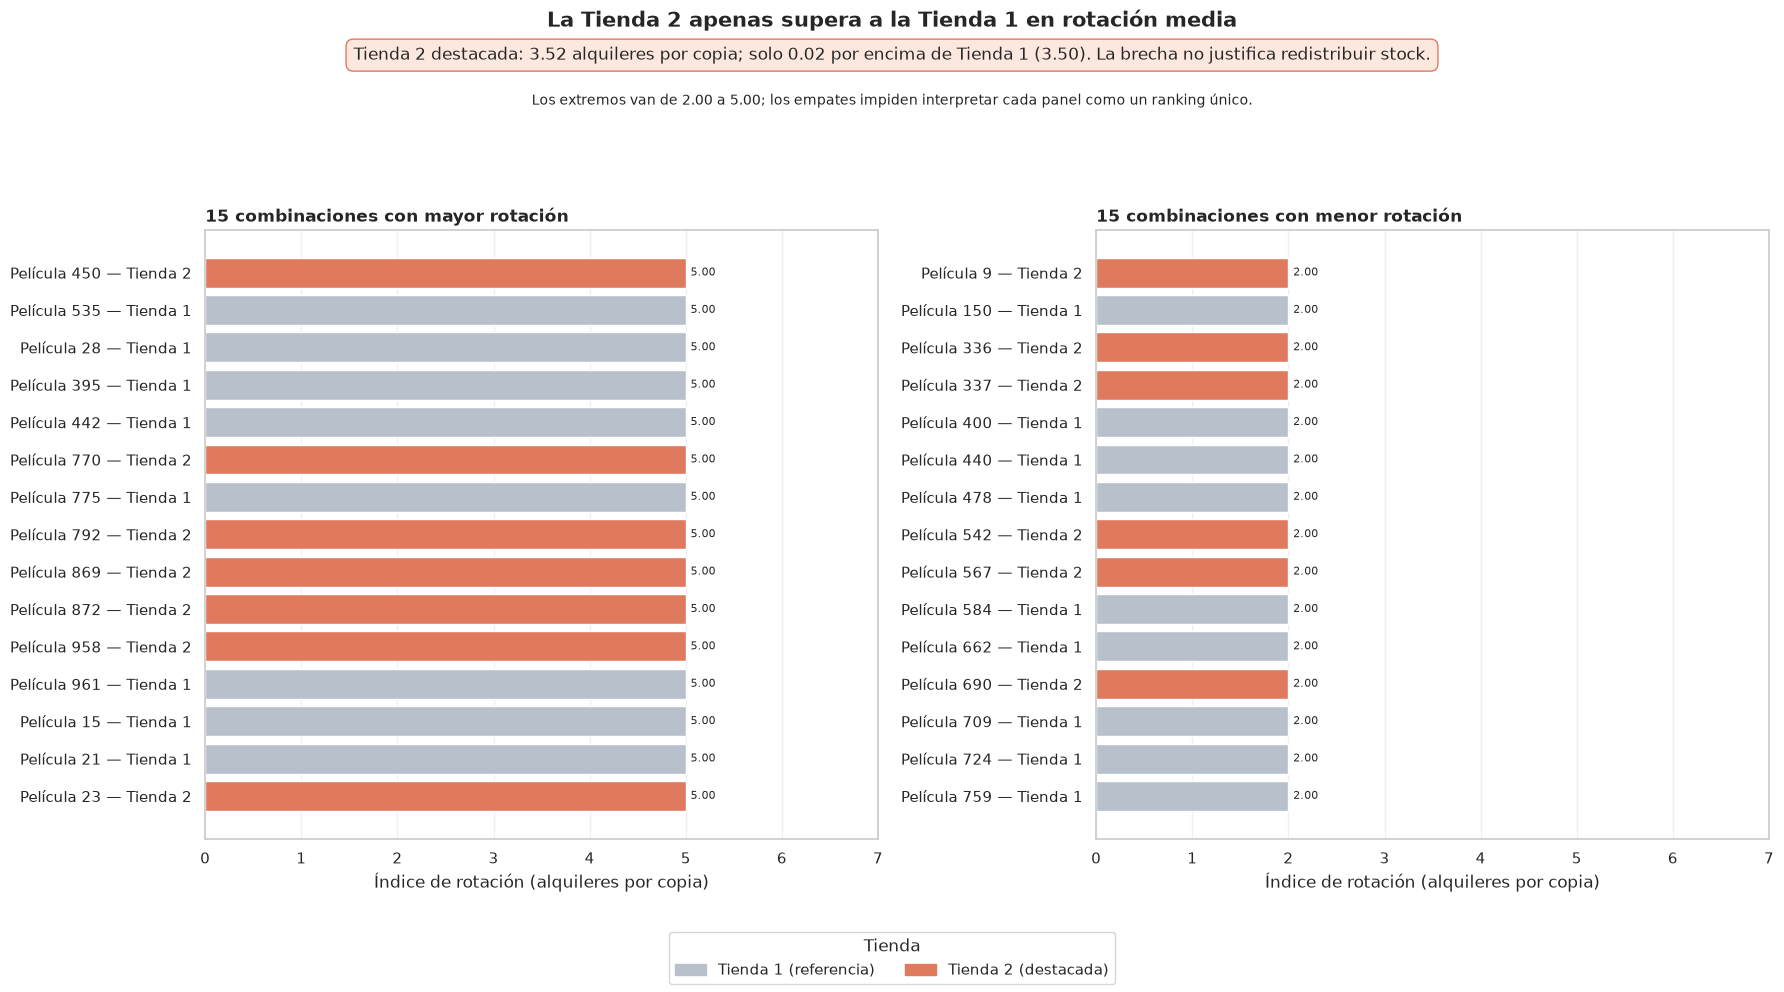

In [18]:
def dibujar_extremos_rotacion(ax, datos, titulo, limite_x, paleta):
    datos = datos.iloc[::-1].copy()
    etiquetas = [
        f"Película {pelicula} — Tienda {tienda}"
        for pelicula, tienda in zip(datos["pelicula"], datos["tienda"])
    ]
    barras = ax.barh(
        etiquetas,
        datos["indice_rotacion"],
        color=[paleta[tienda] for tienda in datos["tienda"]],
    )
    for barra, valor in zip(barras, datos["indice_rotacion"]):
        ax.text(
            barra.get_width() + 0.05,
            barra.get_y() + barra.get_height() / 2,
            f"{valor:.2f}",
            va="center",
            fontsize=8,
        )
    ax.set_title(titulo, loc="left", fontweight="bold")
    ax.set_xlabel("Índice de rotación (alquileres por copia)")
    ax.set_xlim(0, limite_x)
    ax.grid(axis="x", alpha=0.3)
    ax.grid(axis="y", visible=False)


rotacion_maxima = metricas_visualizacion["indice_rotacion"].max()
limite_eje_rotacion = rotacion_maxima + 2
diferencia_rotacion_media = (
    resumen_metricas_a3["rotacion_media"].max()
    - resumen_metricas_a3["rotacion_media"].min()
)
rotacion_media_por_tienda = resumen_metricas_a3.set_index("tienda")["rotacion_media"]
PALETA_ROTACION_NARRATIVA = {1: "#B8C0CC", 2: PALETA_TIENDAS[2]}

fig, ejes = plt.subplots(1, 2, figsize=(18, 10), sharex=True)
dibujar_extremos_rotacion(
    ejes[0], extremos_mayores, "15 combinaciones con mayor rotación", limite_eje_rotacion, PALETA_ROTACION_NARRATIVA
)
dibujar_extremos_rotacion(
    ejes[1], extremos_menores, "15 combinaciones con menor rotación", limite_eje_rotacion, PALETA_ROTACION_NARRATIVA
)
fig.legend(
    handles=[
        Patch(color=PALETA_ROTACION_NARRATIVA[1], label="Tienda 1 (referencia)"),
        Patch(color=PALETA_ROTACION_NARRATIVA[2], label="Tienda 2 (destacada)"),
    ],
    title="Tienda",
    loc="lower center",
    ncol=2,
)
fig.suptitle(
    (
        "La Tienda 2 apenas supera a la Tienda 1 en rotación media"
    ),
    fontsize=15,
    fontweight="bold",
)
fig.text(
    0.5,
    0.93,
    (
        f"Tienda 2 destacada: {rotacion_media_por_tienda.loc[2]:.2f} alquileres por copia; "
        f"solo {diferencia_rotacion_media:.2f} por encima de Tienda 1 ({rotacion_media_por_tienda.loc[1]:.2f}). "
        "La brecha no justifica redistribuir stock."
    ),
    ha="center",
    bbox={"boxstyle": "round,pad=0.45", "facecolor": "#FCE8DF", "edgecolor": PALETA_ROTACION_NARRATIVA[2]},
)
fig.text(
    0.5,
    0.885,
    (
        f"Los extremos van de {metricas_visualizacion['indice_rotacion'].min():.2f} "
        f"a {rotacion_maxima:.2f}; los empates impiden interpretar cada panel como un ranking único."
    ),
    ha="center",
    fontsize=10,
)
fig.tight_layout(rect=[0, 0.08, 1, 0.84]) # type: ignore
ruta_rotacion = GRAFICOS_DIR / "01_rotacion_extremos_por_tienda.png"
fig.savefig(ruta_rotacion, dpi=150, bbox_inches="tight")
plt.show()

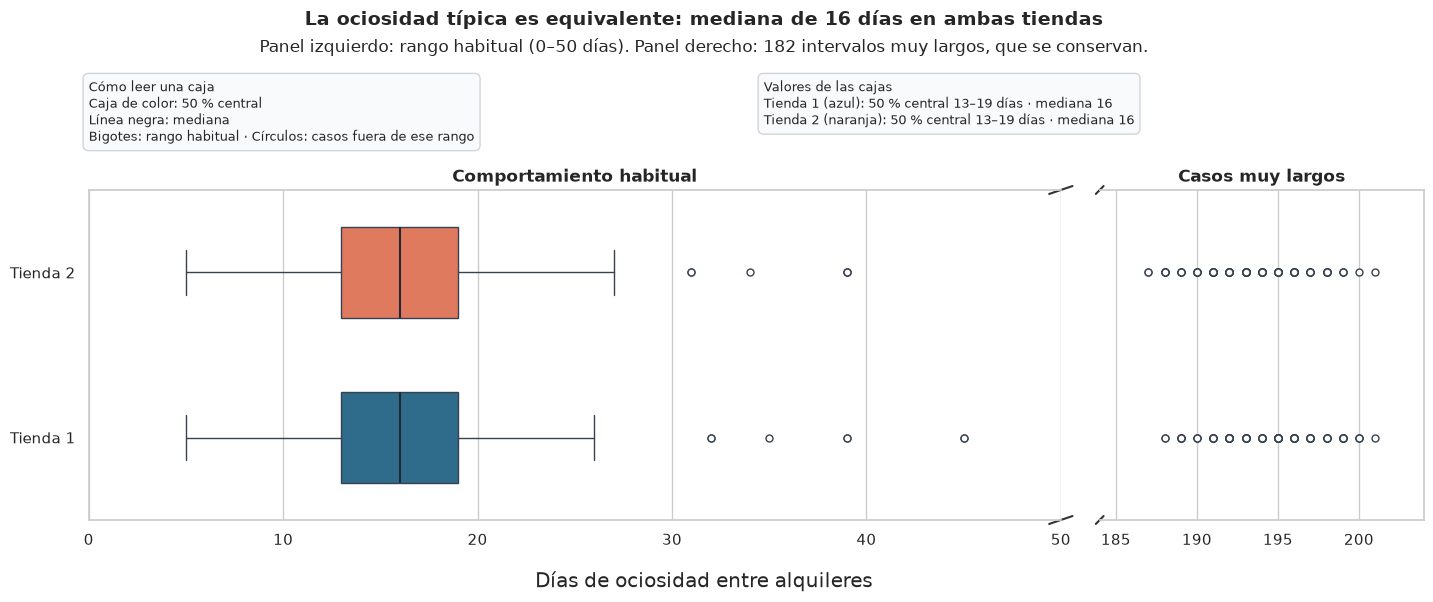

,tienda,intervalos,mediana_dias_ociosidad,promedio_dias_ociosidad,maximo_dias_ociosidad
0,1,5653,16.0,18.89,201.0
1,2,5811,16.0,18.78,201.0


In [19]:
resumen_intervalos_ocio = intervalos_ocio.groupby("tienda", as_index=False).agg(
    intervalos=("dias_ociosidad", "size"),
    mediana_dias_ociosidad=("dias_ociosidad", "median"),
    promedio_dias_ociosidad=("dias_ociosidad", "mean"),
    maximo_dias_ociosidad=("dias_ociosidad", "max"),
)

# Los intervalos de 187 a 201 días aplastan la caja central si se usa un eje continuo.
# Se repite el mismo boxplot en dos tramos horizontales: no se elimina ningún valor.
LIMITE_ZOOM_OCIO = 50
intervalos_fuera_zoom = intervalos_ocio.loc[
    intervalos_ocio["dias_ociosidad"] > LIMITE_ZOOM_OCIO
].copy()
assert not intervalos_fuera_zoom.empty

datos_ocio_por_tienda = [
    intervalos_ocio.loc[intervalos_ocio["tienda"] == tienda, "dias_ociosidad"]
    for tienda in [1, 2]
]

fig, (ax_central, ax_extremos) = plt.subplots(
    1,
    2,
    figsize=(15, 6),
    sharey=True,
    gridspec_kw={"width_ratios": [3, 1], "wspace": 0.06},
)

for ax in (ax_central, ax_extremos):
    cajas = ax.boxplot(
        datos_ocio_por_tienda,
        orientation="horizontal",
        patch_artist=True,
        widths=0.55,
        medianprops={"color": "#1F2937", "linewidth": 1.5},
        boxprops={"edgecolor": "#374151"},
        whiskerprops={"color": "#374151"},
        capprops={"color": "#374151"},
        flierprops={
            "marker": "o",
            "markerfacecolor": "white",
            "markeredgecolor": "#374151",
            "markersize": 5,
        },
    )
    for caja, color in zip(cajas["boxes"], [PALETA_TIENDAS[1], PALETA_TIENDAS[2]]):
        caja.set_facecolor(color)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("")
    ax.set_ylabel("")

medianas_ocio = resumen_intervalos_ocio.set_index("tienda")["mediana_dias_ociosidad"]
cuartiles_ocio = (
    intervalos_ocio.groupby("tienda")["dias_ociosidad"]
    .quantile([0.25, 0.50, 0.75]) # type: ignore
    .unstack()
    .rename(columns={0.25: "q1", 0.50: "mediana", 0.75: "q3"})
)
ax_central.set_xlim(0, LIMITE_ZOOM_OCIO)
ax_extremos.set_xlim(
    intervalos_fuera_zoom["dias_ociosidad"].min() - 3,
    intervalos_fuera_zoom["dias_ociosidad"].max() + 3,
)
ax_central.spines["right"].set_visible(False)
ax_extremos.spines["left"].set_visible(False)
ax_extremos.tick_params(labelleft=False, left=False)

# Marcas diagonales: indican que el eje está cortado, no que se borraron observaciones.
corte = 0.012
kwargs_central = dict(transform=ax_central.transAxes, color="#333333", clip_on=False)
ax_central.plot((1 - corte, 1 + corte), (-corte, corte), **kwargs_central)
ax_central.plot((1 - corte, 1 + corte), (1 - corte, 1 + corte), **kwargs_central)
kwargs_extremos = dict(transform=ax_extremos.transAxes, color="#333333", clip_on=False)
ax_extremos.plot((-corte, corte), (-corte, corte), **kwargs_extremos)
ax_extremos.plot((-corte, corte), (1 - corte, 1 + corte), **kwargs_extremos)

fig.suptitle(
    (
        "La ociosidad típica es equivalente: mediana de "
        f"{medianas_ocio.loc[1]:.0f} días en ambas tiendas"
    ),
    fontsize=14,
    fontweight="bold",
)
fig.text(
    0.5,
    0.91,
    (
        f"Panel izquierdo: rango habitual (0–{LIMITE_ZOOM_OCIO} días). "
        f"Panel derecho: {len(intervalos_fuera_zoom):,} intervalos muy largos, que se conservan."
    ),
    ha="center",
)
fig.text(
    0.09,
    0.865,
    (
        "Cómo leer una caja\n"
        "Caja de color: 50 % central\n"
        "Línea negra: mediana\n"
        "Bigotes: rango habitual · Círculos: casos fuera de ese rango"
    ),
    ha="left",
    va="top",
    fontsize=9,
    bbox={"boxstyle": "round,pad=0.45", "facecolor": "#F9FAFB", "edgecolor": "#D1D5DB"},
)
fig.text(
    0.54,
    0.865,
    (
        "Valores de las cajas\n"
        f"Tienda 1 (azul): 50 % central {cuartiles_ocio.loc[1, 'q1']:.0f}–{cuartiles_ocio.loc[1, 'q3']:.0f} días · mediana {cuartiles_ocio.loc[1, 'mediana']:.0f}\n"
        f"Tienda 2 (naranja): 50 % central {cuartiles_ocio.loc[2, 'q1']:.0f}–{cuartiles_ocio.loc[2, 'q3']:.0f} días · mediana {cuartiles_ocio.loc[2, 'mediana']:.0f}"
    ),
    ha="left",
    va="top",
    fontsize=9,
    bbox={"boxstyle": "round,pad=0.45", "facecolor": "#F9FAFB", "edgecolor": "#D1D5DB"},
)
ax_central.set_yticks([1, 2], ["Tienda 1", "Tienda 2"])
ax_central.set_title("Comportamiento habitual", fontweight="bold")
ax_extremos.set_title("Casos muy largos", fontweight="bold")
fig.supxlabel("Días de ociosidad entre alquileres")
# El eje cortado y la etiqueta global no son compatibles con tight_layout.
# Se reservan márgenes explícitos para el título, subtítulo y etiqueta vertical.
fig.subplots_adjust(left=0.09, right=0.98, bottom=0.13, top=0.68, wspace=0.06)
ruta_ocio = GRAFICOS_DIR / "02_ocio_por_tienda.png"
fig.savefig(ruta_ocio, dpi=150, bbox_inches="tight")
plt.show()
display(resumen_intervalos_ocio.round(2))

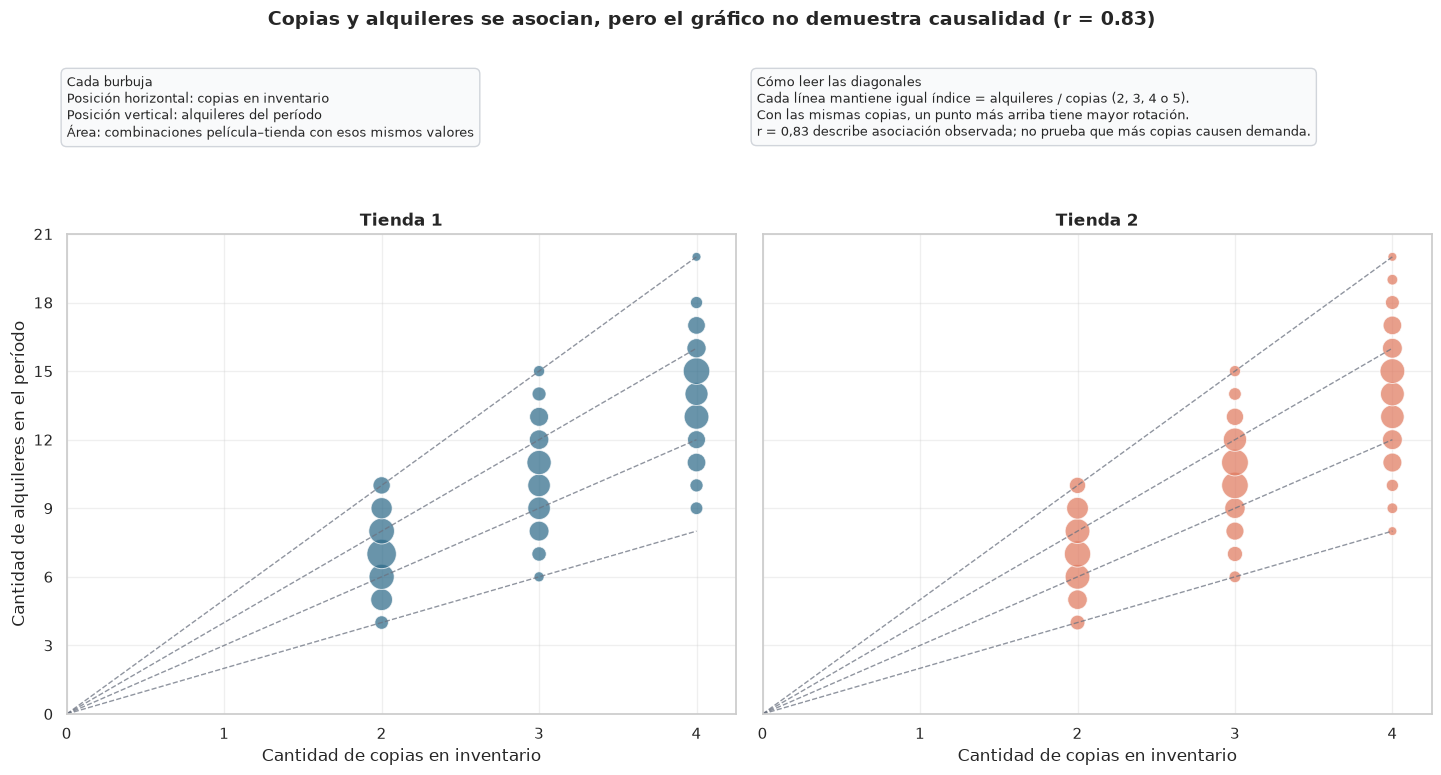

In [20]:
correlacion_copias_alquileres = metricas_visualizacion[
    ["cantidad_copias", "cantidad_alquileres"]
].corr().loc["cantidad_copias", "cantidad_alquileres"]

# Agrupar puntos iguales evita que 1.521 observaciones se tapen entre sí.
# El tamaño de cada burbuja informa cuántas combinaciones película/tienda comparten ese punto.
burbujas_volumen = metricas_visualizacion.groupby(
    ["tienda", "cantidad_copias", "cantidad_alquileres"], as_index=False
).size().rename(columns={"size": "combinaciones"})
burbujas_volumen["tamano"] = 35 + 6 * burbujas_volumen["combinaciones"]

maximo_copias = metricas_visualizacion["cantidad_copias"].max()
maximo_alquileres = metricas_visualizacion["cantidad_alquileres"].max()
linea_copias = np.linspace(0, maximo_copias, 100)

fig, ejes = plt.subplots(1, 2, figsize=(15, 8), sharex=True, sharey=True)
for ax, tienda in zip(ejes, [1, 2]):
    datos_tienda = burbujas_volumen.loc[burbujas_volumen["tienda"] == tienda]
    ax.scatter(
        datos_tienda["cantidad_copias"],
        datos_tienda["cantidad_alquileres"],
        s=datos_tienda["tamano"],
        color=PALETA_TIENDAS[tienda],
        alpha=0.72,
        edgecolors="white",
        linewidths=0.7,
    )
    for indice in [2, 3, 4, 5]:
        ax.plot(
            linea_copias,
            indice * linea_copias,
            color="#6B7280",
            linestyle="--",
            linewidth=1,
            alpha=0.75,
        )
    ax.set_title(f"Tienda {tienda}", fontweight="bold")
    ax.set_xlim(0, maximo_copias + 0.25)
    ax.set_ylim(0, maximo_alquileres + 1)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)

ejes[0].set_ylabel("Cantidad de alquileres en el período")
for ax in ejes:
    ax.set_xlabel("Cantidad de copias en inventario")

fig.suptitle(
    (
        "Copias y alquileres se asocian, pero el gráfico no demuestra causalidad "
        f"(r = {correlacion_copias_alquileres:.2f})"
    ),
    fontsize=14,
    fontweight="bold",
)
fig.text(
    0.07,
    0.90,
    (
        "Cada burbuja\n"
        "Posición horizontal: copias en inventario\n"
        "Posición vertical: alquileres del período\n"
        "Área: combinaciones película–tienda con esos mismos valores"
    ),
    ha="left",
    va="top",
    fontsize=9,
    bbox={"boxstyle": "round,pad=0.45", "facecolor": "#F9FAFB", "edgecolor": "#D1D5DB"},
)
fig.text(
    0.53,
    0.90,
    (
        "Cómo leer las diagonales\n"
        "Cada línea mantiene igual índice = alquileres / copias (2, 3, 4 o 5).\n"
        "Con las mismas copias, un punto más arriba tiene mayor rotación.\n"
        "r = 0,83 describe asociación observada; no prueba que más copias causen demanda."
    ),
    ha="left",
    va="top",
    fontsize=9,
    bbox={"boxstyle": "round,pad=0.45", "facecolor": "#F9FAFB", "edgecolor": "#D1D5DB"},
)
fig.subplots_adjust(left=0.07, right=0.98, bottom=0.10, top=0.70, wspace=0.04)
ruta_dispersion = GRAFICOS_DIR / "03_copias_vs_alquileres.png"
fig.savefig(ruta_dispersion, dpi=150, bbox_inches="tight")
plt.show()

## 20. Hallazgos y decisiones habilitadas

| Hallazgo | Qué se observa | Qué lo explica en los datos | Decisión de negocio que habilita | Gráfico de respaldo |
| --- | --- | --- | --- | --- |
| 1. No hay una brecha operativa de rotación entre tiendas | La rotación media es **3,50** alquileres por copia en la Tienda 1 y **3,52** en la Tienda 2: una diferencia de sólo **0,02**. Los extremos observados van de 2,00 a 5,00. | Los dos inventarios son de tamaño similar (2.270 y 2.311 copias) y los alquileres también (7.923 y 8.121). Además, hay empates en los valores extremos; por eso el gráfico obligatorio no constituye un ranking estricto dentro de cada extremo. | No justificar una redistribución masiva de stock entre tiendas sólo con este índice. Cualquier revisión debe hacerse a nivel de película y complementarse con demanda por período. | `01_rotacion_extremos_por_tienda.png` |
| 2. La ociosidad típica es la misma, pero existen intervalos muy largos | La mediana de los intervalos es **16 días** en ambas tiendas; el rango intercuartílico es de 13 a 19 días. Hay valores extremos de hasta 201 días que el gráfico mantiene visibles. | Se calcularon 11.464 intervalos entre una devolución y el siguiente alquiler. Los extremos son casos puntuales dentro de una distribución central semejante, no evidencia de que una tienda completa tenga peor ociosidad. | Revisar individualmente películas/copias con intervalos excepcionalmente largos antes de decidir bajas o traslados; no aplicar una regla global por tienda. | `02_ocio_por_tienda.png` |
| 3. El volumen bruto de alquileres está condicionado por la cantidad de copias | La asociación lineal entre copias y alquileres es alta (**r = 0,83**). | Una película con más copias tiende a acumular más alquileres aun si cada copia rota a un ritmo comparable. El conteo bruto no separa volumen de eficiencia de inventario. | Priorizar el índice de rotación y la ociosidad para comparar tiendas o películas; usar el total de alquileres sólo como contexto de volumen. | `03_copias_vs_alquileres.png` |

### Limitaciones

- Las métricas describen exclusivamente el período de alquileres registrado, no demanda futura.
- La ociosidad sólo se observa entre dos alquileres consecutivos con una devolución anterior disponible. Los primeros alquileres de cada copia y los alquileres abiertos no aportan un intervalo medible; no se les asignó artificialmente cero días.
- El índice normaliza por cantidad de copias, pero no controla estacionalidad, duración de los alquileres, género, precios, demanda por sucursal ni tiempo de exposición de cada copia. Es útil para comparar el período, no para atribuir causas.